# Credit Card Fraud 2023: Exploratory Data Analysis

Load and clean the local dataset, inspect its fields, and explore feature distributions and correlations. A training-only transformation pipeline imputes missing feature values and scales numeric features.

In [1]:
from pathlib import Path

import pandas as pd

data_path = Path("datasets") / "creditcard_2023.csv"
df = pd.read_csv(data_path)

print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())

print("\nColumn data types:")
display(df.dtypes.rename("dtype").to_frame())

Dataset shape: 568,630 rows × 31 columns


,id,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-0.260648,-0.469648,2.496266,-0.083724,0.129681,0.732898,0.519014,-0.130006,0.727159,...,-0.110552,0.217606,-0.134794,0.165959,0.126280,-0.434824,-0.081230,-0.151045,17982.10,0
1,1,0.985100,-0.356045,0.558056,-0.429654,0.277140,0.428605,0.406466,-0.133118,0.347452,...,-0.194936,-0.605761,0.079469,-0.577395,0.190090,0.296503,-0.248052,-0.064512,6531.37,0
2,2,-0.260272,-0.949385,1.728538,-0.457986,0.074062,1.419481,0.743511,-0.095576,-0.261297,...,-0.005020,0.702906,0.945045,-1.154666,-0.605564,-0.312895,-0.300258,-0.244718,2513.54,0
3,3,-0.152152,-0.508959,1.746840,-1.090178,0.249486,1.143312,0.518269,-0.065130,-0.205698,...,-0.146927,-0.038212,-0.214048,-1.893131,1.003963,-0.515950,-0.165316,0.048424,5384.44,0
4,4,-0.206820,-0.165280,1.527053,-0.448293,0.106125,0.530549,0.658849,-0.212660,1.049921,...,-0.106984,0.729727,-0.161666,0.312561,-0.414116,1.071126,0.023712,0.419117,14278.97,0



Column data types:


,dtype
id,int64
V1,float64
V2,float64
V3,float64
V4,float64
V5,float64
V6,float64
V7,float64
V8,float64
V9,float64


## Missing values and data preparation

Keep the raw data unchanged. Remove the record ID, duplicate rows, and rows without a target. Treat `Class` as the binary target. A training-only transformation pipeline imputes missing feature values and scales every numeric feature, including `Amount`.

In [2]:
import numpy as np

missing_summary = pd.DataFrame({
    "missing_values": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
})
print(f"Total missing values: {int(df.isna().sum().sum()):,}")
display(missing_summary)

# Exclude the identifier, remove duplicate records, and discard rows without a label.
df_prepared = df.drop(columns="id").copy()
duplicate_rows = int(df_prepared.duplicated().sum())
missing_target_rows = int(df_prepared["Class"].isna().sum())
df_prepared = df_prepared.drop_duplicates().dropna(subset=["Class"]).copy()
df_prepared["Class"] = df_prepared["Class"].astype("category")

print(f"Rows retained: {len(df_prepared):,} of {len(df):,}")
print(f"Duplicate rows removed: {duplicate_rows:,}")
print(f"Rows removed for missing target: {missing_target_rows:,}")
print("Class counts:")
display(df_prepared["Class"].value_counts().sort_index().rename("transactions").to_frame())
print("Prepared data types:")
display(df_prepared.dtypes.rename("prepared_dtype").to_frame())

Total missing values: 0


,missing_values,missing_percent
id,0,0.0
V1,0,0.0
V2,0,0.0
V3,0,0.0
V4,0,0.0
V5,0,0.0
V6,0,0.0
V7,0,0.0
V8,0,0.0
V9,0,0.0


Rows retained: 568,630 of 568,630
Class counts:


,transactions
Class,
0,284315
1,284315


Prepared data types:


,prepared_dtype
V1,float64
V2,float64
V3,float64
V4,float64
V5,float64
V6,float64
V7,float64
V8,float64
V9,float64
V10,float64


## Training, validation, and test sets

Split the cleaned data into 70% training, 15% validation, and 15% test sets. Stratification preserves the class balance in each set. `Class` is the target.

In [3]:
from sklearn.model_selection import train_test_split

X = df_prepared.drop(columns="Class").replace([np.inf, -np.inf], np.nan)
y = df_prepared["Class"]

# First set aside 15% for testing, then split the remainder into 70% train and 15% validation.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=(0.15 / 0.85), random_state=42, stratify=y_train
)

print(f"Training set:   {len(X_train):,} rows ({len(X_train) / len(df_prepared):.1%})")
print(f"Validation set: {len(X_val):,} rows ({len(X_val) / len(df_prepared):.1%})")
print(f"Test set:       {len(X_test):,} rows ({len(X_test) / len(df_prepared):.1%})")



Training set:   398,040 rows (70.0%)
Validation set: 85,295 rows (15.0%)
Test set:       85,295 rows (15.0%)


## Feature cleaning and scaling pipeline

Replace infinite feature values with missing values, impute missing values using each training feature's median, then standardize features using training-set statistics. Fit the pipeline on the training data only and reuse it to transform validation and test data.

In [7]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

preprocessing_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

X_train_scaled = pd.DataFrame(
    preprocessing_pipeline.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index,
)
X_val_scaled = pd.DataFrame(
    preprocessing_pipeline.transform(X_val),
    columns=X_val.columns,
    index=X_val.index,
)
X_test_scaled = pd.DataFrame(
    preprocessing_pipeline.transform(X_test),
    columns=X_test.columns,
    index=X_test.index,
)

print(f"Missing or infinite training feature values imputed: {int(X_train.isna().sum().sum()):,}")
print("Scaled training feature means and standard deviations:")
display(pd.DataFrame({"mean": X_train_scaled.mean(), "std": X_train_scaled.std(ddof=0)}).round(3))

Missing or infinite training feature values imputed: 0
Scaled training feature means and standard deviations:


,mean,std
V1,-0.0,1.0
V2,0.0,1.0
V3,0.0,1.0
V4,-0.0,1.0
V5,0.0,1.0
V6,-0.0,1.0
V7,-0.0,1.0
V8,-0.0,1.0
V9,0.0,1.0
V10,-0.0,1.0


## Feature and target correlations

The Pearson correlation matrix and heatmap include all numeric features and the `Class` target. Correlations are calculated on the training set to keep validation and test data out of exploratory model analysis.

Pearson correlation matrix:


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
V1,1.00,-0.56,0.48,-0.50,0.52,0.35,0.56,-0.22,0.55,0.60,...,-0.03,-0.08,-0.07,-0.02,-0.01,0.01,-0.12,0.07,-0.0,-0.51
V2,-0.56,1.00,-0.63,0.58,-0.63,-0.34,-0.69,0.19,-0.59,-0.62,...,-0.02,0.04,0.15,-0.03,0.13,0.01,0.05,0.03,0.0,0.49
V3,0.48,-0.63,1.00,-0.69,0.51,0.51,0.62,-0.26,0.65,0.71,...,-0.02,-0.04,-0.06,0.08,-0.08,-0.05,-0.19,0.01,-0.0,-0.68
V4,-0.50,0.58,-0.69,1.00,-0.43,-0.47,-0.58,0.20,-0.68,-0.71,...,-0.02,0.09,0.04,-0.10,0.03,0.14,0.19,-0.01,0.0,0.74
V5,0.52,-0.63,0.51,-0.43,1.00,0.24,0.58,-0.31,0.48,0.56,...,0.04,-0.12,-0.11,-0.09,-0.04,0.05,-0.04,0.10,0.0,-0.34
V6,0.35,-0.34,0.51,-0.47,0.24,1.00,0.41,-0.60,0.43,0.47,...,-0.04,0.04,0.31,-0.01,-0.20,-0.07,-0.26,-0.07,0.0,-0.43
V7,0.56,-0.69,0.62,-0.58,0.58,0.41,1.00,-0.18,0.59,0.67,...,0.02,-0.10,-0.11,-0.00,0.00,-0.01,-0.01,0.03,0.0,-0.48
V8,-0.22,0.19,-0.26,0.20,-0.31,-0.60,-0.18,1.00,-0.21,-0.20,...,0.06,-0.10,-0.46,0.08,0.32,0.04,0.30,0.05,-0.0,0.14
V9,0.55,-0.59,0.65,-0.68,0.48,0.43,0.59,-0.21,1.00,0.75,...,0.13,-0.21,-0.04,0.04,-0.03,-0.13,-0.11,0.07,-0.0,-0.59
V10,0.60,-0.62,0.71,-0.71,0.56,0.47,0.67,-0.20,0.75,1.00,...,0.04,-0.15,-0.06,0.04,-0.01,-0.05,-0.13,0.04,-0.0,-0.67


Feature correlations with the Class target (sorted by absolute strength):


,correlation_with_Class
V14,-0.806
V12,-0.769
V4,0.736
V11,0.724
V3,-0.682
V10,-0.673
V9,-0.586
V16,-0.572
V1,-0.505
V2,0.493


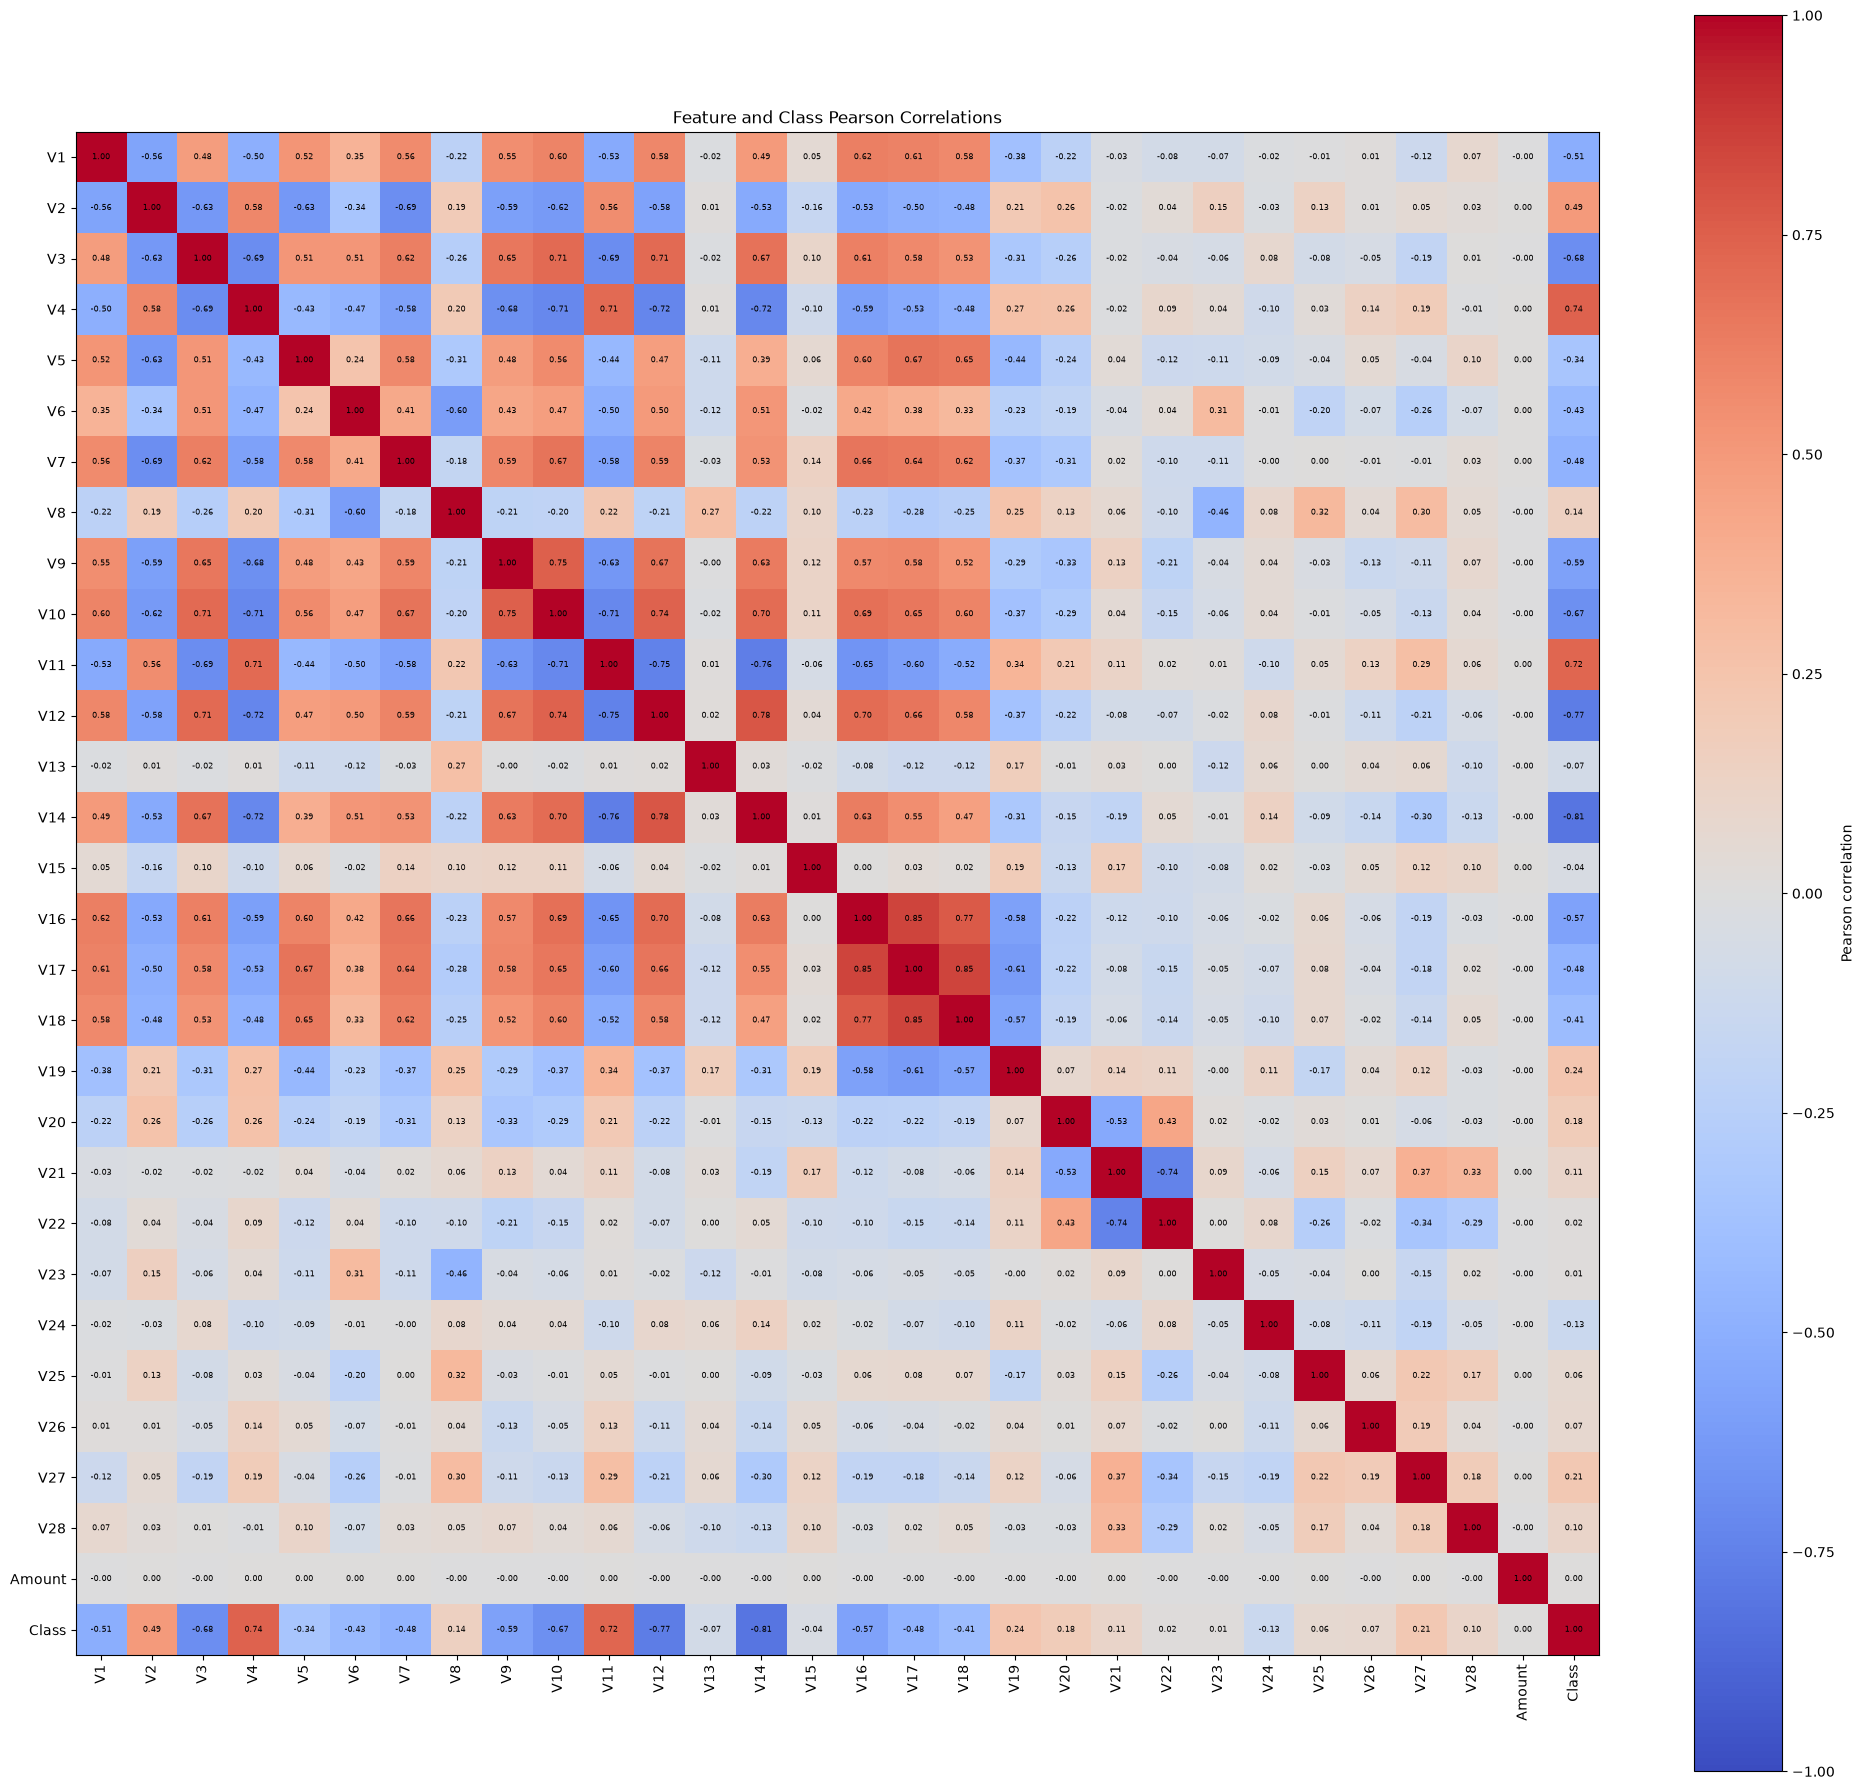

In [4]:
training_data = X_train.copy()
training_data["Class"] = y_train.astype(int)
correlation_matrix = training_data.corr()

print("Pearson correlation matrix:")
display(correlation_matrix.round(2))

print("Feature correlations with the Class target (sorted by absolute strength):")
target_correlations = (
    correlation_matrix["Class"]
    .drop("Class")
    .sort_values(key=abs, ascending=False)
    .rename("correlation_with_Class")
    .to_frame()
    .round(3)
)
display(target_correlations)

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(20, 18))
heatmap = ax.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)
labels = correlation_matrix.columns
ax.set_xticks(range(len(labels)), labels=labels, rotation=90)
ax.set_yticks(range(len(labels)), labels=labels)
ax.set_title("Feature and Class Pearson Correlations")
fig.colorbar(heatmap, ax=ax, label="Pearson correlation")

for row in range(len(labels)):
    for column in range(len(labels)):
        ax.text(
            column,
            row,
            f"{correlation_matrix.iat[row, column]:.2f}",
            ha="center",
            va="center",
            fontsize=6,
        )

fig.tight_layout()
plt.show()

## Mean, median, and standard deviation

Statistics cover V1–V28 and `Amount`. The record ID is excluded, and class balance is shown separately above because `Class` is a label.

In [5]:
feature_columns = [column for column in df_prepared.columns if column.startswith("V")] + ["Amount"]
statistics = pd.DataFrame({
    "mean": df_prepared[feature_columns].mean(),
    "median": df_prepared[feature_columns].median(),
    "std_deviation": df_prepared[feature_columns].std(),
}).round(3)
display(statistics)

,mean,median,std_deviation
V1,-0.000,-0.094,1.000
V2,-0.000,-0.136,1.000
V3,0.000,0.000,1.000
V4,0.000,-0.074,1.000
V5,0.000,0.081,1.000
V6,0.000,0.079,1.000
V7,0.000,0.233,1.000
V8,0.000,-0.115,1.000
V9,0.000,0.093,1.000
V10,0.000,0.263,1.000


## Feature distributions

Histograms show all 28 standardized features and transaction amount. A separate bar chart shows the two class counts.

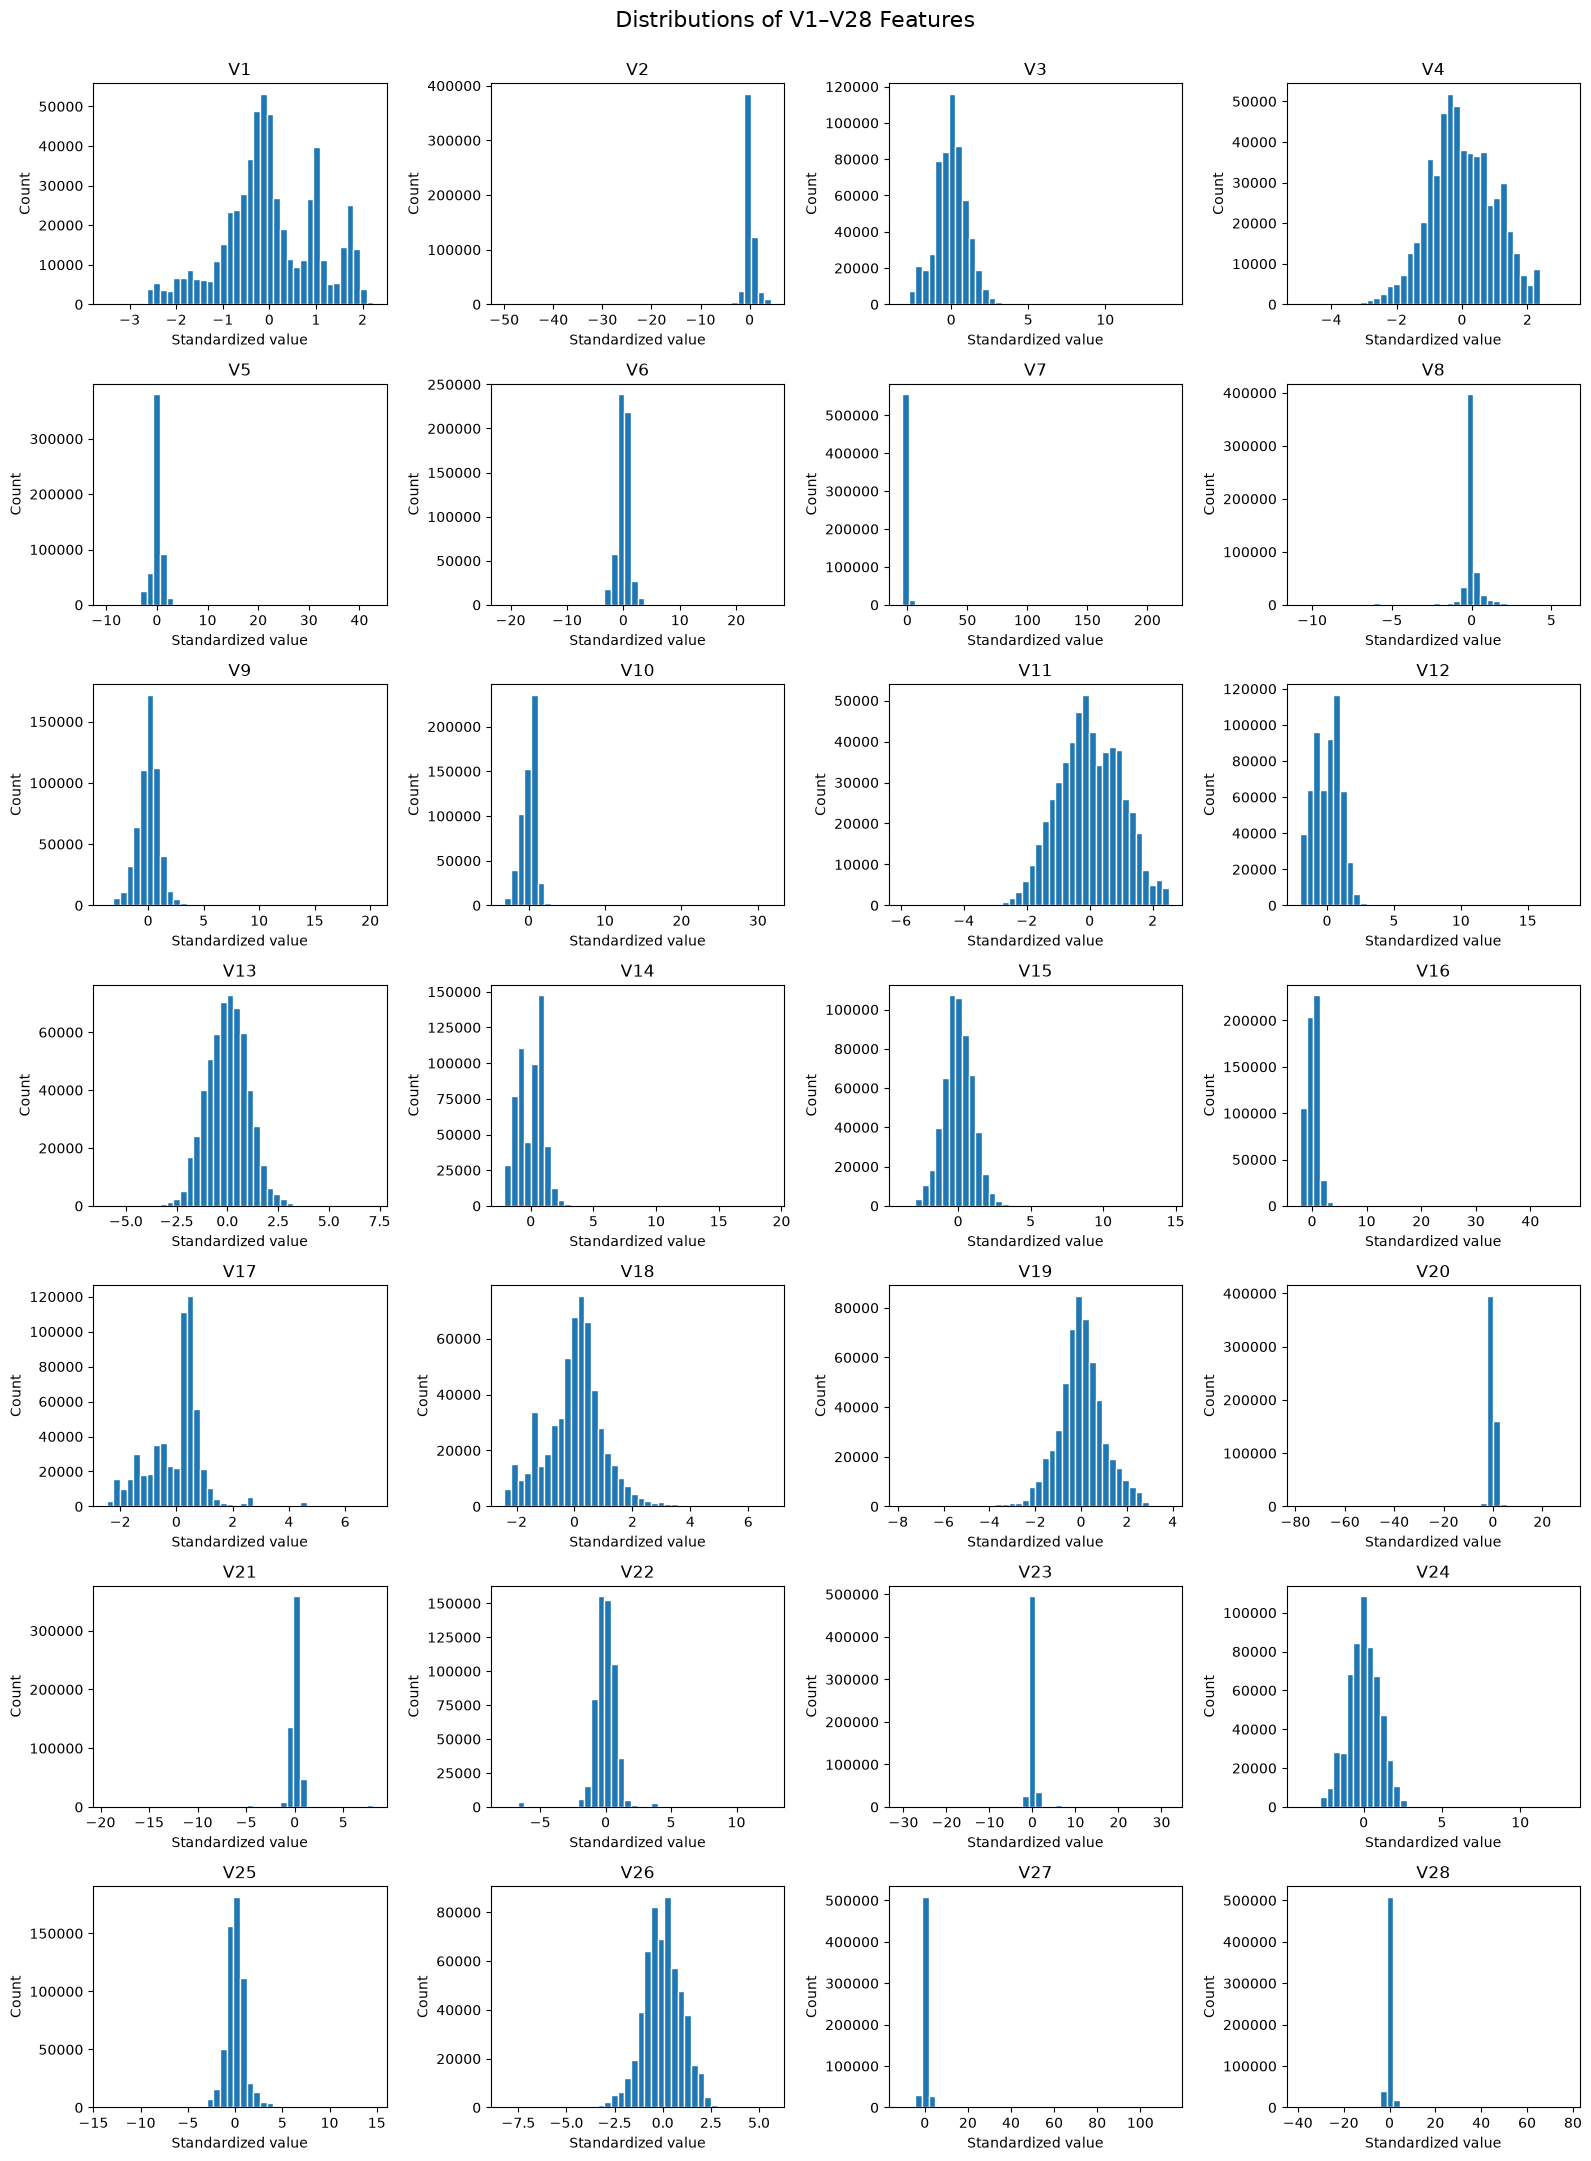

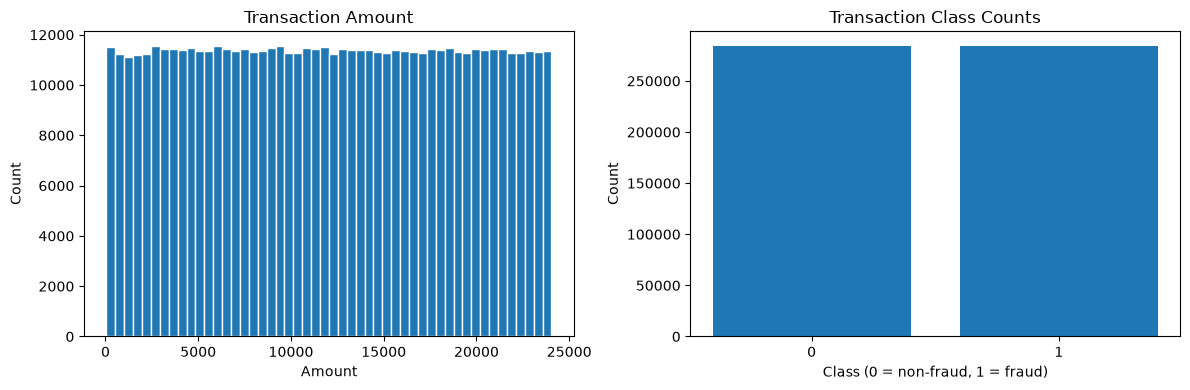

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(7, 4, figsize=(16, 22))
for column, ax in zip([column for column in df_prepared.columns if column.startswith("V")], axes.flat):
    ax.hist(df_prepared[column], bins=40, edgecolor="white")
    ax.set_title(column)
    ax.set_xlabel("Standardized value")
    ax.set_ylabel("Count")
fig.suptitle("Distributions of V1–V28 Features", fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df_prepared["Amount"], bins=50, edgecolor="white")
axes[0].set_title("Transaction Amount")
axes[0].set_xlabel("Amount")
axes[0].set_ylabel("Count")

class_counts = df_prepared["Class"].value_counts().sort_index()
axes[1].bar(class_counts.index.astype(str), class_counts.values)
axes[1].set_title("Transaction Class Counts")
axes[1].set_xlabel("Class (0 = non-fraud, 1 = fraud)")
axes[1].set_ylabel("Count")
fig.tight_layout()
plt.show()